# 04 · Mối quan hệ giữa các biến nhiều chiều

Tương quan tuyến tính và thứ hạng, phụ thuộc đuôi, cấu trúc nhân tố (PCA), quan hệ dẫn–trễ,
và quan hệ khối lượng–biến động, cho **20 mã** (7 ngành; mã sắp theo ngành, nhãn tô màu theo ngành,
vạch đen phân cách ngành trên các heatmap). Ma trận đầy đủ 20×20 gồm 190 cặp không có hướng / 380 cặp có hướng.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.4f}".format)
con = U.connect()
SYMBOLS = U.SYMBOLS
COL = U.SYMBOL_COLORS
from scipy import stats
import statsmodels.api as sm
from scipy.stats import rankdata
from statsmodels.stats.multitest import multipletests

SECTOR, SECTORS, SC = U.SECTOR, U.SECTORS, U.SECTOR_COLORS


def sector_style(ax, labels, axis="both", sep=True, fs=9):
    """Tô màu nhãn trục theo ngành và kẻ vạch phân cách ngành trên heatmap (nhãn theo thứ tự U.SYMBOLS)."""
    ticks = range(len(labels))
    if axis in ("both", "x"):
        ax.set_xticks(ticks, labels, rotation=90, fontsize=fs)
        for t, s in zip(ax.get_xticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if axis in ("both", "y"):
        ax.set_yticks(ticks, labels, fontsize=fs)
        for t, s in zip(ax.get_yticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if sep:
        cuts = [i - 0.5 for i in range(1, len(labels)) if SECTOR[labels[i]] != SECTOR[labels[i - 1]]]
        for c in cuts:
            ax.axhline(c, color="black", lw=0.8); ax.axvline(c, color="black", lw=0.8)


def big_heatmap(ax, matrix, fs_cell=6.5, annotate=True, **kw):
    """Heatmap 20x20: chữ trong ô nhỏ (hoặc bỏ), nhãn tô màu theo ngành, vạch phân cách ngành."""
    im = U.make_heatmap(ax, matrix, **kw)
    for t in list(ax.texts):
        if annotate: t.set_fontsize(fs_cell)
        else: t.remove()
    sector_style(ax, list(matrix.index))
    return im


def sector_legend(ax_or_fig, **kw):
    from matplotlib.patches import Patch
    h = [Patch(color=SC[s], label=s) for s in SECTORS]
    return ax_or_fig.legend(handles=h, **kw)

In [2]:
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
print(r.shape)
pairs = [(a, b) for i, a in enumerate(SYMBOLS) for b in SYMBOLS[i + 1:]]          # 190 cặp không có hướng
pair_names = [f"{a}-{b}" for a, b in pairs]
same_sector = np.array([SECTOR[a] == SECTOR[b] for a, b in pairs])
print(f"{len(pairs)} cặp: {same_sector.sum()} cặp cùng ngành, {(~same_sector).sum()} cặp khác ngành")

(2118, 20)
190 cặp: 34 cặp cùng ngành, 156 cặp khác ngành


## 1. Ma trận tương quan: Pearson, Spearman, Kendall

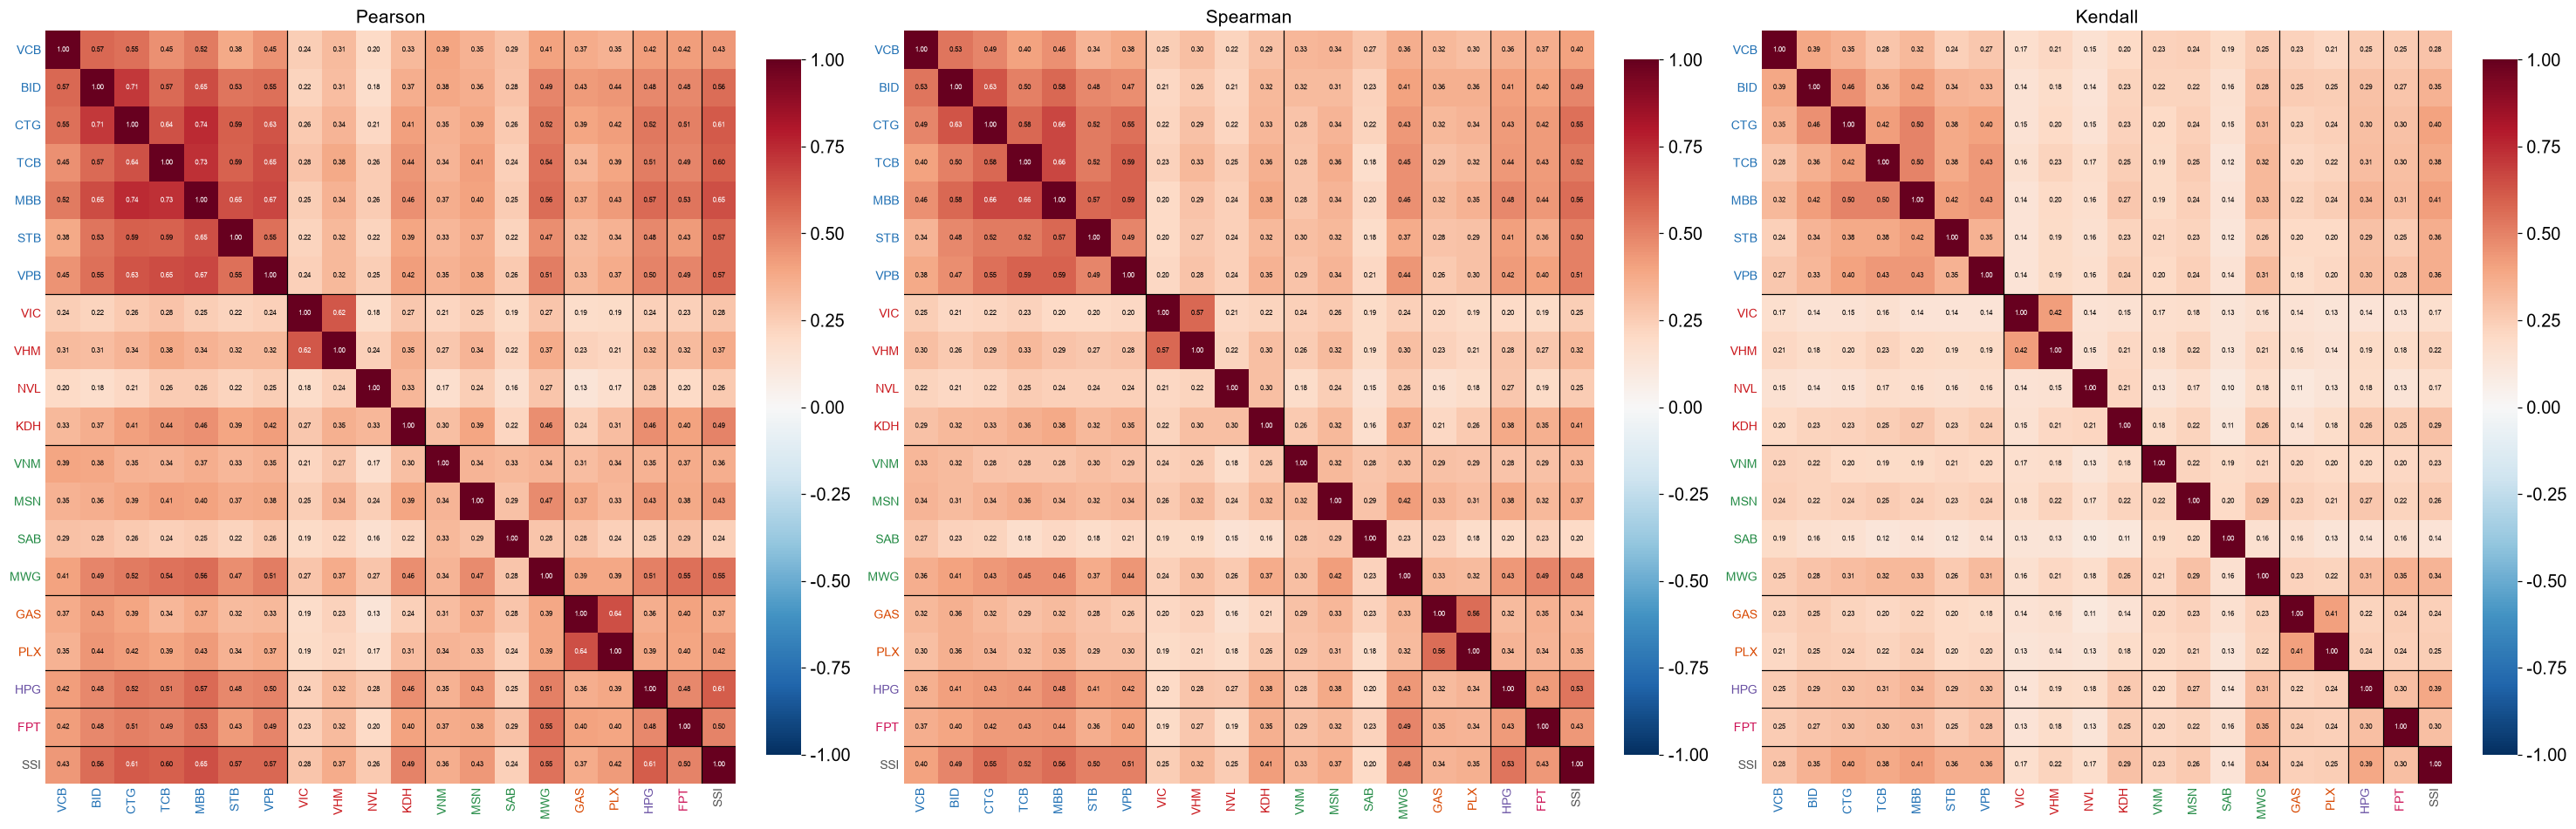

Tương quan 190 cặp (min / trung vị / trung bình / max):
        pearson  spearman  kendall
min      0.1260    0.1460   0.0980
median   0.3690    0.3220   0.2240
mean     0.3850    0.3370   0.2370
max      0.7440    0.6650   0.4970

Cao nhất: {'MBB-SSI': 0.646, 'MBB-STB': 0.646, 'BID-MBB': 0.653, 'TCB-VPB': 0.653, 'MBB-VPB': 0.665, 'BID-CTG': 0.706, 'TCB-MBB': 0.732, 'CTG-MBB': 0.744}
Thấp nhất: {'NVL-GAS': 0.126, 'NVL-SAB': 0.16, 'NVL-PLX': 0.165, 'NVL-VNM': 0.168, 'BID-NVL': 0.178, 'VIC-NVL': 0.185, 'VIC-GAS': 0.187, 'VIC-SAB': 0.189}


In [3]:
corrs = {m: r.corr(method=m) for m in ("pearson", "spearman", "kendall")}
fig, axes = plt.subplots(1, 3, figsize=(27, 8.8))
for ax, (m, c) in zip(axes, corrs.items()):
    big_heatmap(ax, c, fs_cell=5.5, vmin=-1, vmax=1, title=m.capitalize())
U.finalize_figure(fig, "04_correlation_heatmaps")
plt.show()
for m, c in corrs.items():
    U.save_table(c, f"04_corr_{m}")

iu = np.triu_indices(len(SYMBOLS), 1)
off = pd.DataFrame({m: c.values[iu] for m, c in corrs.items()}, index=pair_names)
print("Tương quan 190 cặp (min / trung vị / trung bình / max):")
print(off.agg(["min", "median", "mean", "max"]).round(3))
srt = off["pearson"].sort_values()
print("\nCao nhất:", srt.tail(8).round(3).to_dict())
print("Thấp nhất:", srt.head(8).round(3).to_dict())

**Tương quan theo ngành.** Trung bình Pearson giữa các mã của từng cặp ngành (đường chéo = trung bình các cặp trong cùng ngành; ngành chỉ có 1 mã để trống).

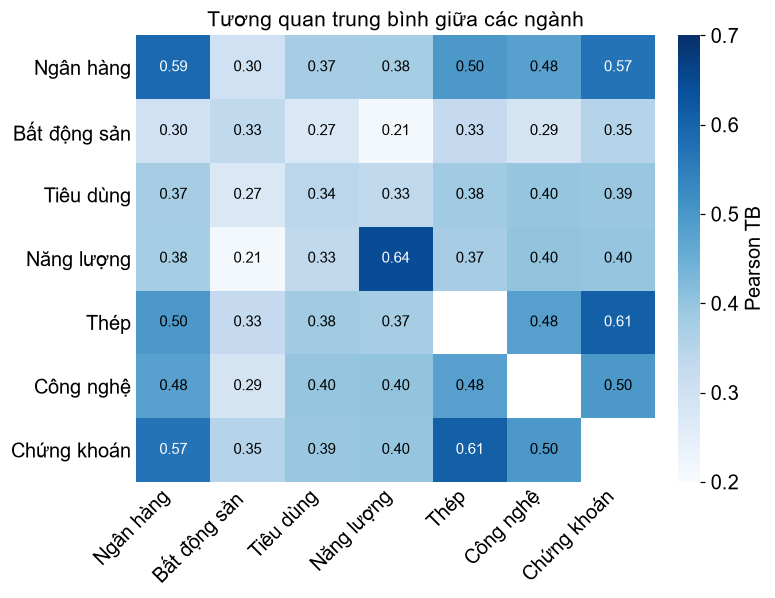

Pearson trung bình: cùng ngành 0.502 | khác ngành 0.360


,Ngân hàng,Bất động sản,Tiêu dùng,Năng lượng,Thép,Công nghệ,Chứng khoán
Ngân hàng,0.5900,0.3000,0.3700,0.3800,0.5000,0.4800,0.5700
Bất động sản,0.3000,0.3300,0.2700,0.2100,0.3300,0.2900,0.3500
Tiêu dùng,0.3700,0.2700,0.3400,0.3300,0.3800,0.4000,0.3900
Năng lượng,0.3800,0.2100,0.3300,0.6400,0.3700,0.4000,0.4000
Thép,0.5000,0.3300,0.3800,0.3700,NaN,0.4800,0.6100
Công nghệ,0.4800,0.2900,0.4000,0.4000,0.4800,NaN,0.5000
Chứng khoán,0.5700,0.3500,0.3900,0.4000,0.6100,0.5000,NaN


In [4]:
C = corrs["pearson"]
sec_corr = pd.DataFrame(np.nan, index=SECTORS, columns=SECTORS)
for sa in SECTORS:
    for sb in SECTORS:
        ma, mb = [s for s in SYMBOLS if SECTOR[s] == sa], [s for s in SYMBOLS if SECTOR[s] == sb]
        blk = C.loc[ma, mb].values
        if sa == sb:
            if len(ma) > 1: sec_corr.loc[sa, sb] = blk[np.triu_indices(len(ma), 1)].mean()
        else:
            sec_corr.loc[sa, sb] = blk.mean()
U.save_table(sec_corr, "04_corr_by_sector")
fig, ax = plt.subplots(figsize=(7.2, 5.6))
U.make_heatmap(ax, sec_corr, cmap="Blues", vmin=0.2, vmax=0.7, cbar_label="Pearson TB", title="Tương quan trung bình giữa các ngành")
ax.set_xticks(range(len(SECTORS)), SECTORS, rotation=45, ha="right")
U.finalize_figure(fig, "04_corr_by_sector")
plt.show()
within_mean = C.values[iu][same_sector].mean(); between_mean = C.values[iu][~same_sector].mean()
print(f"Pearson trung bình: cùng ngành {within_mean:.3f} | khác ngành {between_mean:.3f}")
sec_corr.round(2)

## 2. Ma trận phân tán (scatter matrix) của lợi suất — 5 mã gốc

Ma trận phân tán 20×20 (400 ô) không đọc được nên chỉ vẽ cho 5 mã gốc (VHM, NVL, STB, VPB, HPG); toàn bộ 20 mã được thể hiện bằng heatmap tương quan ở mục 1.

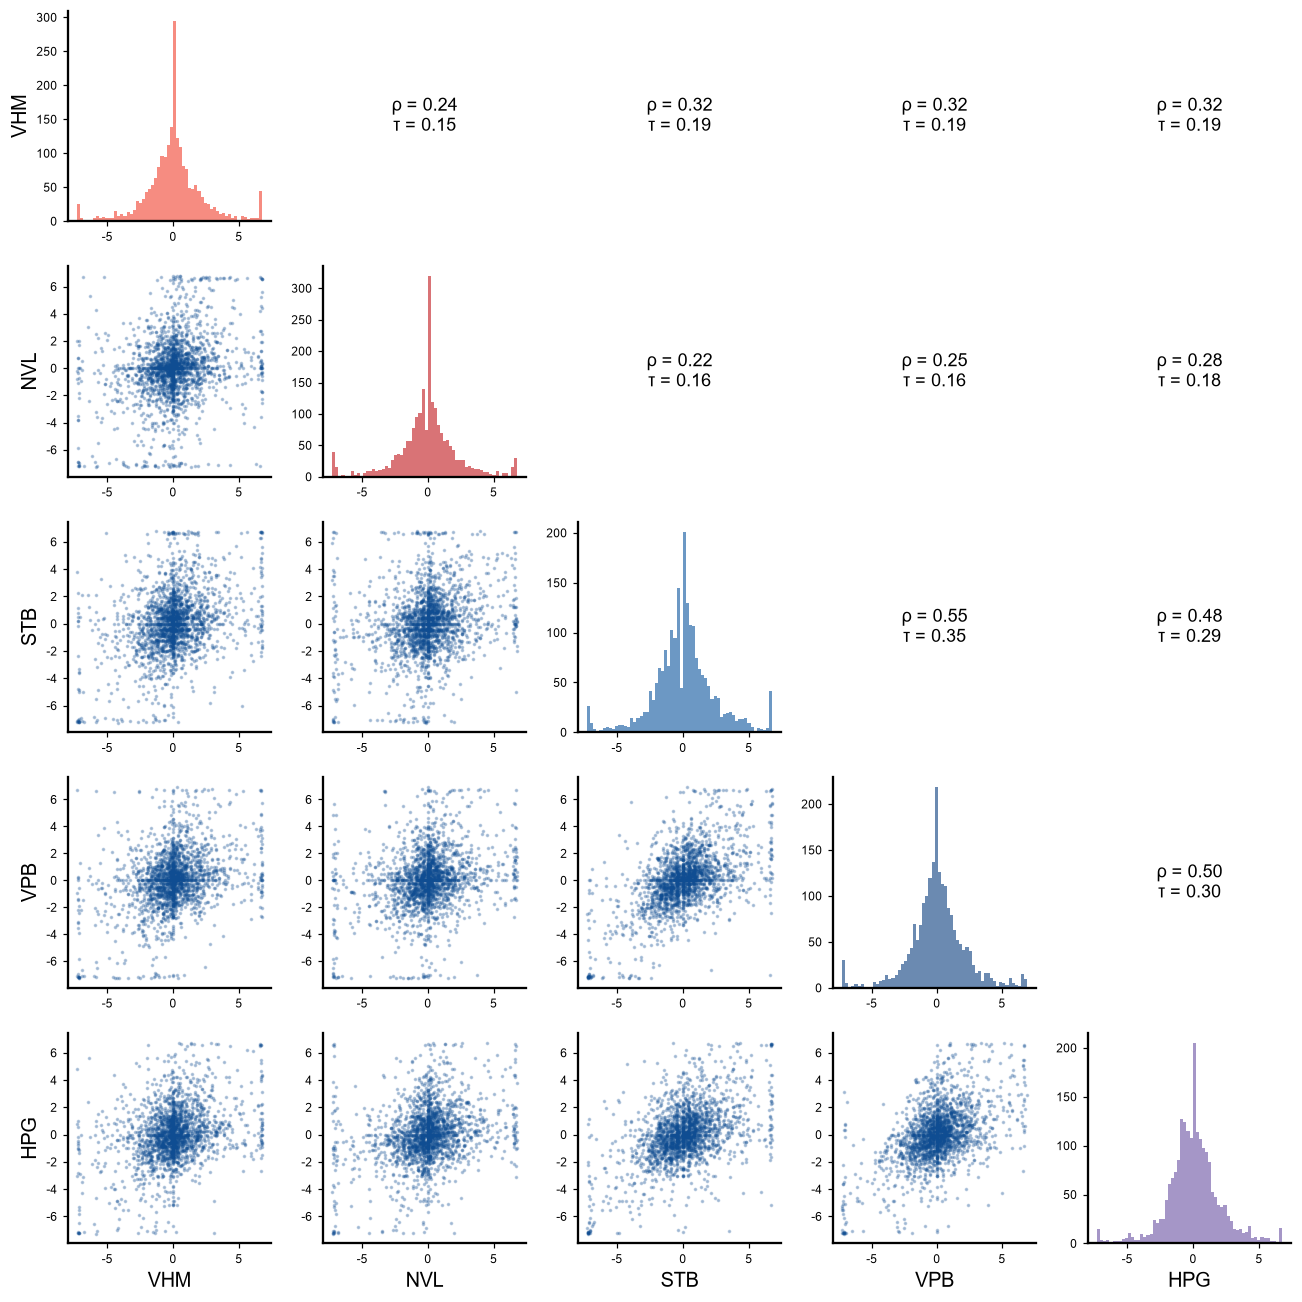

In [5]:
ORIG = U.ORIGINAL_SYMBOLS      # scatter matrix 20×20 (400 ô) không đọc được: vẽ cho 5 mã gốc; toàn bộ 20 mã xem heatmap ở mục 1
n = len(ORIG)
fig, axes = plt.subplots(n, n, figsize=(12, 12))
for i, a in enumerate(ORIG):
    for j, b in enumerate(ORIG):
        ax = axes[i, j]
        if i == j:
            ax.hist(100 * r[a], bins=60, color=COL[a], alpha=0.6)
        elif i > j:
            ax.scatter(100 * r[b], 100 * r[a], s=2, alpha=0.25, color=U.PALETTE["blue_main"])
        else:
            ax.text(0.5, 0.5, f"ρ = {corrs['pearson'].loc[a, b]:.2f}\nτ = {corrs['kendall'].loc[a, b]:.2f}",
                    ha="center", va="center", transform=ax.transAxes, fontsize=12)
            ax.set_axis_off()
        if j == 0: ax.set_ylabel(a)
        if i == n - 1: ax.set_xlabel(b)
        ax.tick_params(labelsize=8)
U.finalize_figure(fig, "04_scatter_matrix")
plt.show()

## 3. Tương quan động (cửa sổ trượt 120 phiên)

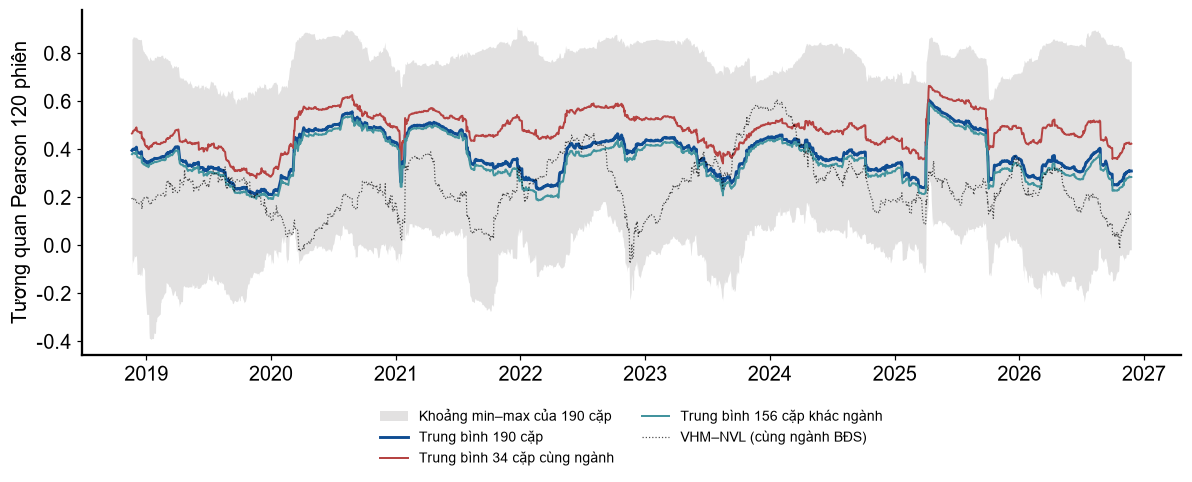

Tương quan trung bình 190 cặp: min 0.21 (19/11/2019), max 0.61 (11/04/2025), cả kỳ 0.38
Cùng ngành 0.48 | khác ngành 0.36 | khoảng cách trung bình 0.12
Trung bình theo năm: {2018: 0.38, 2019: 0.3, 2020: 0.45, 2021: 0.41, 2022: 0.37, 2023: 0.38, 2024: 0.38, 2025: 0.42, 2026: 0.32}


In [6]:
W = 120
roll = pd.DataFrame({k: r[a].rolling(W).corr(r[b]) for k, (a, b) in zip(pair_names, pairs)})
avg_corr = roll.mean(axis=1)
within = roll.loc[:, same_sector].mean(axis=1)       # trung bình các cặp cùng ngành
between = roll.loc[:, ~same_sector].mean(axis=1)     # trung bình các cặp khác ngành

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.fill_between(roll.index, roll.min(axis=1), roll.max(axis=1), color=U.PALETTE["neutral"], alpha=0.6,
                lw=0, label=f"Khoảng min–max của {len(pairs)} cặp")
ax.plot(avg_corr.index, avg_corr, color=U.PALETTE["blue_main"], lw=1.9, label=f"Trung bình {len(pairs)} cặp")
ax.plot(within.index, within, color=U.PALETTE["red_strong"], lw=1.3, label=f"Trung bình {same_sector.sum()} cặp cùng ngành")
ax.plot(between.index, between, color=U.PALETTE["teal"], lw=1.3, label=f"Trung bình {(~same_sector).sum()} cặp khác ngành")
ax.plot(roll.index, roll["VHM-NVL"], color="black", lw=0.8, alpha=0.7, ls=":", label="VHM–NVL (cùng ngành BĐS)")
ax.set_ylabel(f"Tương quan Pearson {W} phiên")
ax.legend(fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
U.finalize_figure(fig, "04_rolling_correlation")
plt.show()
print(f"Tương quan trung bình {len(pairs)} cặp: min {avg_corr.min():.2f} ({avg_corr.idxmin():%d/%m/%Y}), max {avg_corr.max():.2f} ({avg_corr.idxmax():%d/%m/%Y}), cả kỳ {avg_corr.mean():.2f}")
print(f"Cùng ngành {within.mean():.2f} | khác ngành {between.mean():.2f} | khoảng cách trung bình {(within - between).mean():.2f}")
print("Trung bình theo năm:", avg_corr.groupby(avg_corr.index.year).mean().round(2).to_dict())

## 4. Tương quan trong giai đoạn căng thẳng và bình thường

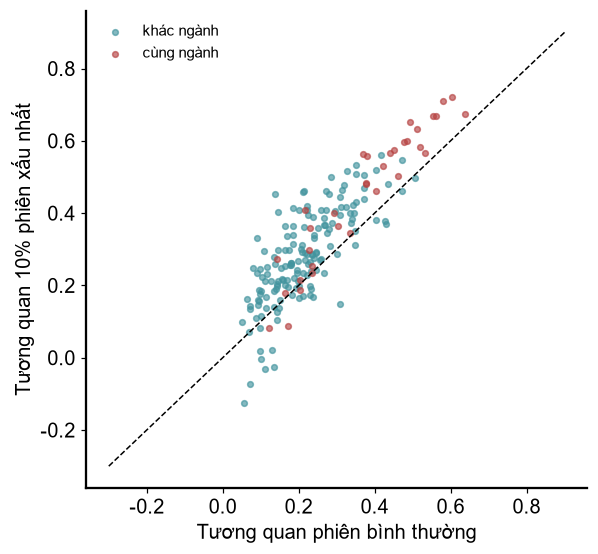

Số phiên căng thẳng: 212
Trung bình tương quan: bình thường 0.243 -> căng thẳng 0.314
Số cặp có tương quan GIẢM khi căng thẳng: 33 / 190
Trung bình thay đổi: cùng ngành 0.081 | khác ngành 0.068


,bình thường (90% còn lại),căng thẳng (10% phiên xấu nhất),cùng ngành,thay đổi
NVL-GAS,0.0572,-0.1261,False,-0.1833
VCB-NVL,0.1349,-0.0267,False,-0.1617
VCB-SSI,0.3080,0.1482,False,-0.1598
BID-NVL,0.0728,-0.0727,False,-0.1455
STB-KDH,0.2124,0.4572,False,0.2448
VNM-FPT,0.2133,0.4619,False,0.2486
STB-PLX,0.1447,0.4025,False,0.2578
SAB-FPT,0.1386,0.4542,False,0.3156


In [7]:
mkt = r.mean(axis=1)                                   # danh mục đều 20 mã làm đại diện "thị trường"
stress = mkt <= mkt.quantile(0.10)
calm_c, stress_c = r[~stress].corr(), r[stress].corr()
cmp_ = pd.DataFrame({
    "bình thường (90% còn lại)": calm_c.values[iu],
    "căng thẳng (10% phiên xấu nhất)": stress_c.values[iu],
    "cùng ngành": same_sector,
}, index=pair_names)
cmp_["thay đổi"] = cmp_.iloc[:, 1] - cmp_.iloc[:, 0]
U.save_table(cmp_, "04_corr_stress_vs_calm")

fig, ax = plt.subplots(figsize=(5.6, 5.2))
for flag, col, lab in [(False, U.PALETTE["teal"], "khác ngành"), (True, U.PALETTE["red_strong"], "cùng ngành")]:
    d = cmp_[cmp_["cùng ngành"] == flag]
    ax.scatter(d.iloc[:, 0], d.iloc[:, 1], s=14, alpha=0.65, color=col, label=lab)
ax.plot([-0.3, 0.9], [-0.3, 0.9], color="black", lw=1, ls="--")
ax.set_xlabel("Tương quan phiên bình thường"); ax.set_ylabel("Tương quan 10% phiên xấu nhất")
ax.legend(fontsize=10)
U.finalize_figure(fig, "04_corr_stress_vs_calm")
plt.show()
print(f"Số phiên căng thẳng: {int(stress.sum())}")
print("Trung bình tương quan: bình thường %.3f -> căng thẳng %.3f" % (cmp_.iloc[:, 0].mean(), cmp_.iloc[:, 1].mean()))
print("Số cặp có tương quan GIẢM khi căng thẳng: %d / %d" % ((cmp_["thay đổi"] < 0).sum(), len(cmp_)))
print("Trung bình thay đổi: cùng ngành %.3f | khác ngành %.3f" % (cmp_.loc[cmp_["cùng ngành"], "thay đổi"].mean(), cmp_.loc[~cmp_["cùng ngành"], "thay đổi"].mean()))
cmp_.sort_values("thay đổi").iloc[[0, 1, 2, 3, -4, -3, -2, -1]]

## 5. Phụ thuộc đuôi dưới thực nghiệm

$\hat\lambda_L(q) = \dfrac{\#\{U_{1t}\le q,\ U_{2t}\le q\}}{n\,q}$ với $U$ là hạng chuẩn hoá. So với
giá trị kỳ vọng nếu phụ thuộc là chuẩn (Gaussian copula) cùng hệ số tương quan.

Sai số nội suy λ_Gauss lớn nhất trên 190 cặp: 1.02e-05


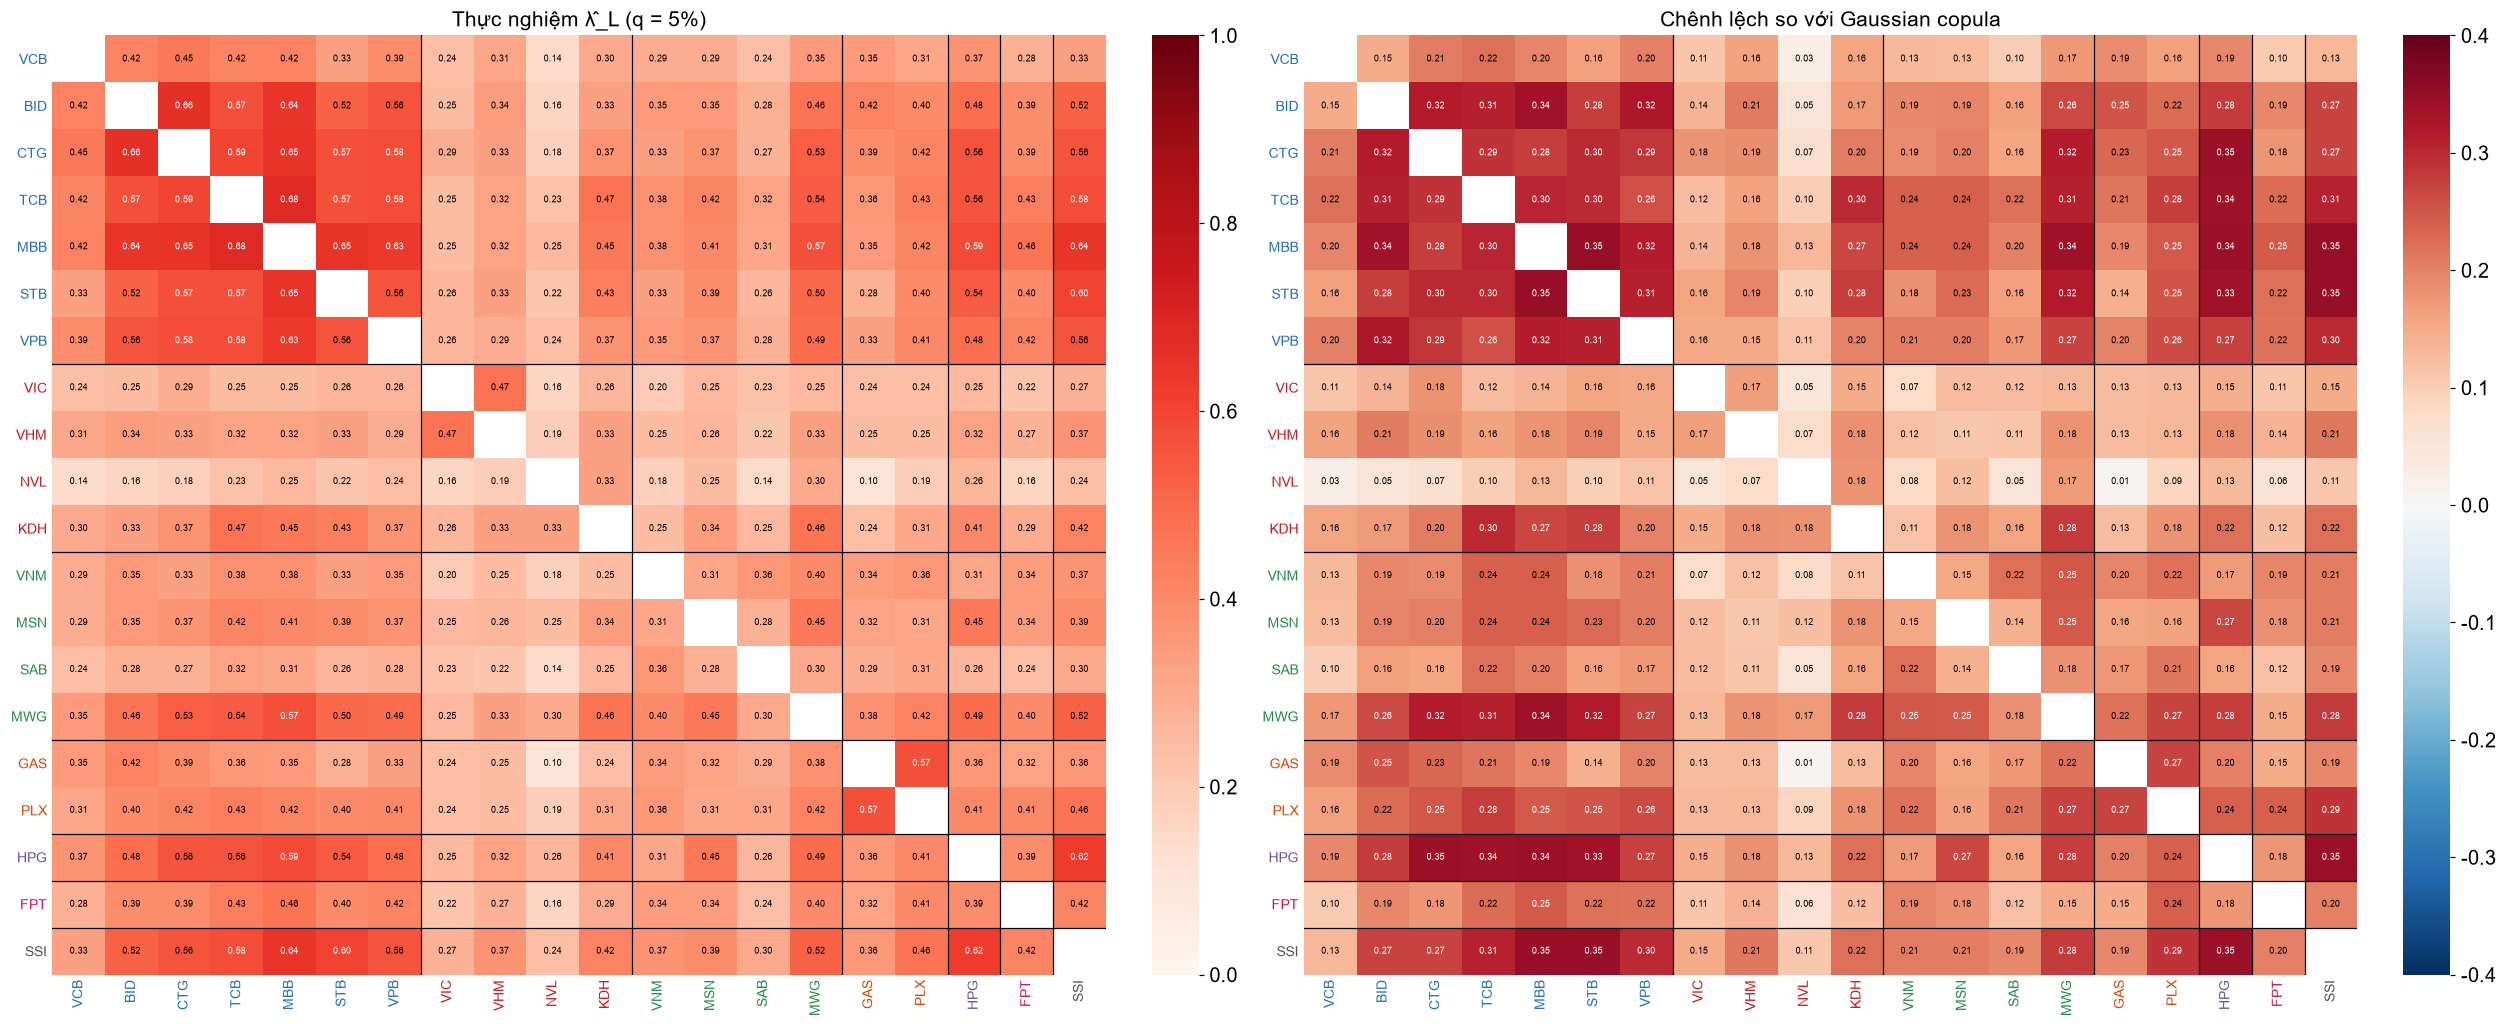

WindowsPath('D:/2026.1/Đồ án II/report/table/eda/04_lower_tail_dependence.csv')

In [8]:
Q = 0.05
zq = stats.norm.ppf(Q)
# λ_Gauss chỉ phụ thuộc ρ -> tính sẵn trên lưới ρ rồi nội suy (nhanh hơn nhiều khi bootstrap 190 cặp × 1.000 lần)
RH = np.linspace(-0.95, 0.99, 300)
LG = np.array([stats.multivariate_normal([0, 0], [[1, p], [p, 1]]).cdf([zq, zq]) for p in RH]) / Q

def tail_mats(x):
    """x: mảng n×p lợi suất. Trả về (λ̂_L thực nghiệm, λ_Gauss) dạng ma trận p×p."""
    n = len(x)
    ranks = rankdata(x, axis=0)
    ind = (ranks / (n + 1) <= Q).astype(float)
    lam = ind.T @ ind / (n * Q)
    rho = 2 * np.sin(np.pi / 6 * np.corrcoef(ranks.T))      # ρ Pearson suy từ ρ Spearman (Gaussian copula)
    return lam, np.interp(rho, RH, LG)

lam_emp, lam_g = tail_mats(r.values)
lamL = pd.DataFrame(lam_emp, index=SYMBOLS, columns=SYMBOLS).mask(np.eye(len(SYMBOLS), dtype=bool))
lamG = pd.DataFrame(lam_g, index=SYMBOLS, columns=SYMBOLS).mask(np.eye(len(SYMBOLS), dtype=bool))

# kiểm tra sai số nội suy so với công thức chính xác (mvn.cdf) trên 190 cặp
rho_s = 2 * np.sin(np.pi / 6 * corrs["spearman"].values[iu])
exact = np.array([stats.multivariate_normal([0, 0], [[1, p], [p, 1]]).cdf([zq, zq]) / Q for p in rho_s])
print(f"Sai số nội suy λ_Gauss lớn nhất trên 190 cặp: {np.abs(exact - lam_g[iu]).max():.2e}")

fig, axes = plt.subplots(1, 2, figsize=(23, 9.5))
big_heatmap(axes[0], lamL, fs_cell=6, cmap="Reds", vmin=0, vmax=1, title=f"Thực nghiệm λ̂_L (q = {Q:.0%})")
big_heatmap(axes[1], lamL - lamG, fs_cell=6, cmap="RdBu_r", vmin=-0.4, vmax=0.4,
            title="Chênh lệch so với Gaussian copula")
U.finalize_figure(fig, "04_lower_tail_dependence")
plt.show()
U.save_table(lamL, "04_lower_tail_dependence")

**Độ bất định:** mỗi λ̂_L chỉ dựa trên vài chục phiên đồng thời rơi vào đuôi, nên ước lượng khoảng tin
cậy 95% cho chênh lệch $\hat\lambda_L - \lambda_{Gauss}$ bằng **bootstrap khối** (khối 20 phiên, 1.000 lần)
để giữ cấu trúc biến động cụm.

In [9]:
rng = np.random.default_rng(42)
B, BLOCK, n = 1000, 20, len(r)
rv = r.values
starts_all = np.arange(n - BLOCK + 1)
diff_obs = (lam_emp - lam_g)[iu]
boot = np.empty((B, len(pairs)))
for b in range(B):
    starts = rng.choice(starts_all, size=int(np.ceil(n / BLOCK)))
    idx = (starts[:, None] + np.arange(BLOCK)).ravel()[:n]
    lb, gb = tail_mats(rv[idx])
    boot[b] = (lb - gb)[iu]
tail_ci = pd.DataFrame({
    "λ̂_L": lam_emp[iu],
    "λ_Gauss": lam_g[iu],
    "λ̂_L − λ_Gauss": diff_obs,
    "CI 2,5%": np.percentile(boot, 2.5, axis=0),
    "CI 97,5%": np.percentile(boot, 97.5, axis=0),
    "cùng ngành": same_sector,
}, index=pair_names)
tail_ci["CI loại trừ 0"] = tail_ci["CI 2,5%"] > 0
U.save_table(tail_ci, "04_tail_dependence_bootstrap")
print(f"B = {B} lần, khối {BLOCK} phiên; CI 95% từng cặp (chưa hiệu chỉnh đa kiểm định).")
print(f"λ̂_L: trung bình {tail_ci['λ̂_L'].mean():.3f} (độc lập = {Q}); λ_Gauss trung bình {tail_ci['λ_Gauss'].mean():.3f}")
print("Chênh lệch λ̂_L − λ_Gauss: min %.3f | trung bình %.3f | max %.3f" % tuple(tail_ci["λ̂_L − λ_Gauss"].agg(["min", "mean", "max"])))
print(f"Cặp có CI loại trừ 0: {int(tail_ci['CI loại trừ 0'].sum())}/{len(tail_ci)}; cặp có chênh lệch > 0: {(tail_ci['λ̂_L − λ_Gauss'] > 0).sum()}")
for flag, lab in [(True, "cùng ngành"), (False, "khác ngành")]:
    d = tail_ci[tail_ci["cùng ngành"] == flag]
    print(f"{lab}: λ̂_L TB {d['λ̂_L'].mean():.3f} | λ_Gauss TB {d['λ_Gauss'].mean():.3f} | chênh lệch TB {d['λ̂_L − λ_Gauss'].mean():.3f} | CI>0: {int(d['CI loại trừ 0'].sum())}/{len(d)}")
tail_ci.sort_values("λ̂_L", ascending=False).head(10)

B = 1000 lần, khối 20 phiên; CI 95% từng cặp (chưa hiệu chỉnh đa kiểm định).
λ̂_L: trung bình 0.369 (độc lập = 0.05); λ_Gauss trung bình 0.171
Chênh lệch λ̂_L − λ_Gauss: min 0.010 | trung bình 0.199 | max 0.349
Cặp có CI loại trừ 0: 184/190; cặp có chênh lệch > 0: 190
cùng ngành: λ̂_L TB 0.466 | λ_Gauss TB 0.233 | chênh lệch TB 0.234 | CI>0: 33/34
khác ngành: λ̂_L TB 0.348 | λ_Gauss TB 0.157 | chênh lệch TB 0.191 | CI>0: 151/156


,λ̂_L,λ_Gauss,λ̂_L − λ_Gauss,"CI 2,5%","CI 97,5%",cùng ngành,CI loại trừ 0
TCB-MBB,0.6799,0.3758,0.3041,0.2276,0.3830,True,True
BID-CTG,0.6610,0.3441,0.3169,0.2515,0.4102,True,True
CTG-MBB,0.6516,0.3761,0.2754,0.1955,0.3944,True,True
MBB-STB,0.6516,0.3030,0.3486,0.2740,0.4348,True,True
MBB-SSI,0.6421,0.2936,0.3485,0.2503,0.4132,False,True
BID-MBB,0.6421,0.3063,0.3358,0.2658,0.4059,True,True
MBB-VPB,0.6327,0.3172,0.3154,0.2273,0.3820,True,True
HPG-SSI,0.6232,0.2770,0.3462,0.2402,0.3991,False,True
STB-SSI,0.6043,0.2549,0.3494,0.2493,0.4401,False,True
CTG-TCB,0.5949,0.3071,0.2878,0.2026,0.3948,True,True


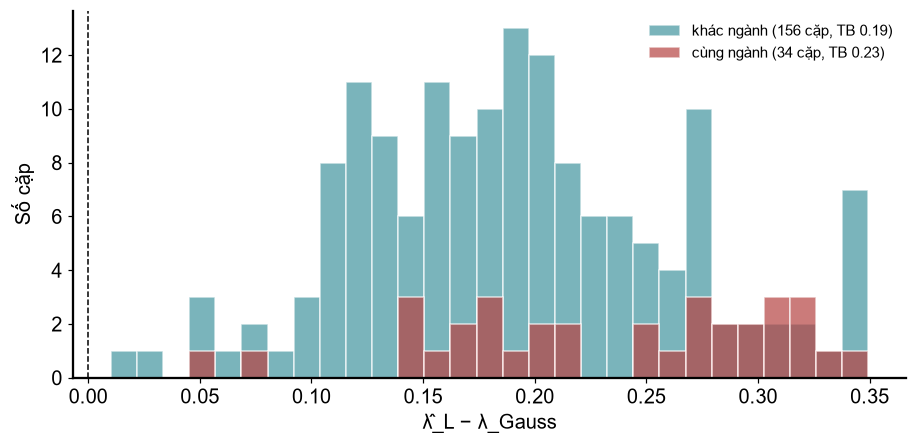

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bins = np.linspace(tail_ci["λ̂_L − λ_Gauss"].min(), tail_ci["λ̂_L − λ_Gauss"].max(), 30)
for flag, col, lab in [(False, U.PALETTE["teal"], "khác ngành"), (True, U.PALETTE["red_strong"], "cùng ngành")]:
    d = tail_ci[tail_ci["cùng ngành"] == flag]["λ̂_L − λ_Gauss"]
    ax.hist(d, bins=bins, alpha=0.7, color=col, edgecolor="white", label=f"{lab} ({len(d)} cặp, TB {d.mean():.2f})")
ax.axvline(0, color="black", lw=1, ls="--")
ax.set_xlabel("λ̂_L − λ_Gauss"); ax.set_ylabel("Số cặp"); ax.legend(fontsize=10)
U.finalize_figure(fig, "04_lower_tail_dependence_dist")
plt.show()

## 6. Phân tích thành phần chính (PCA)

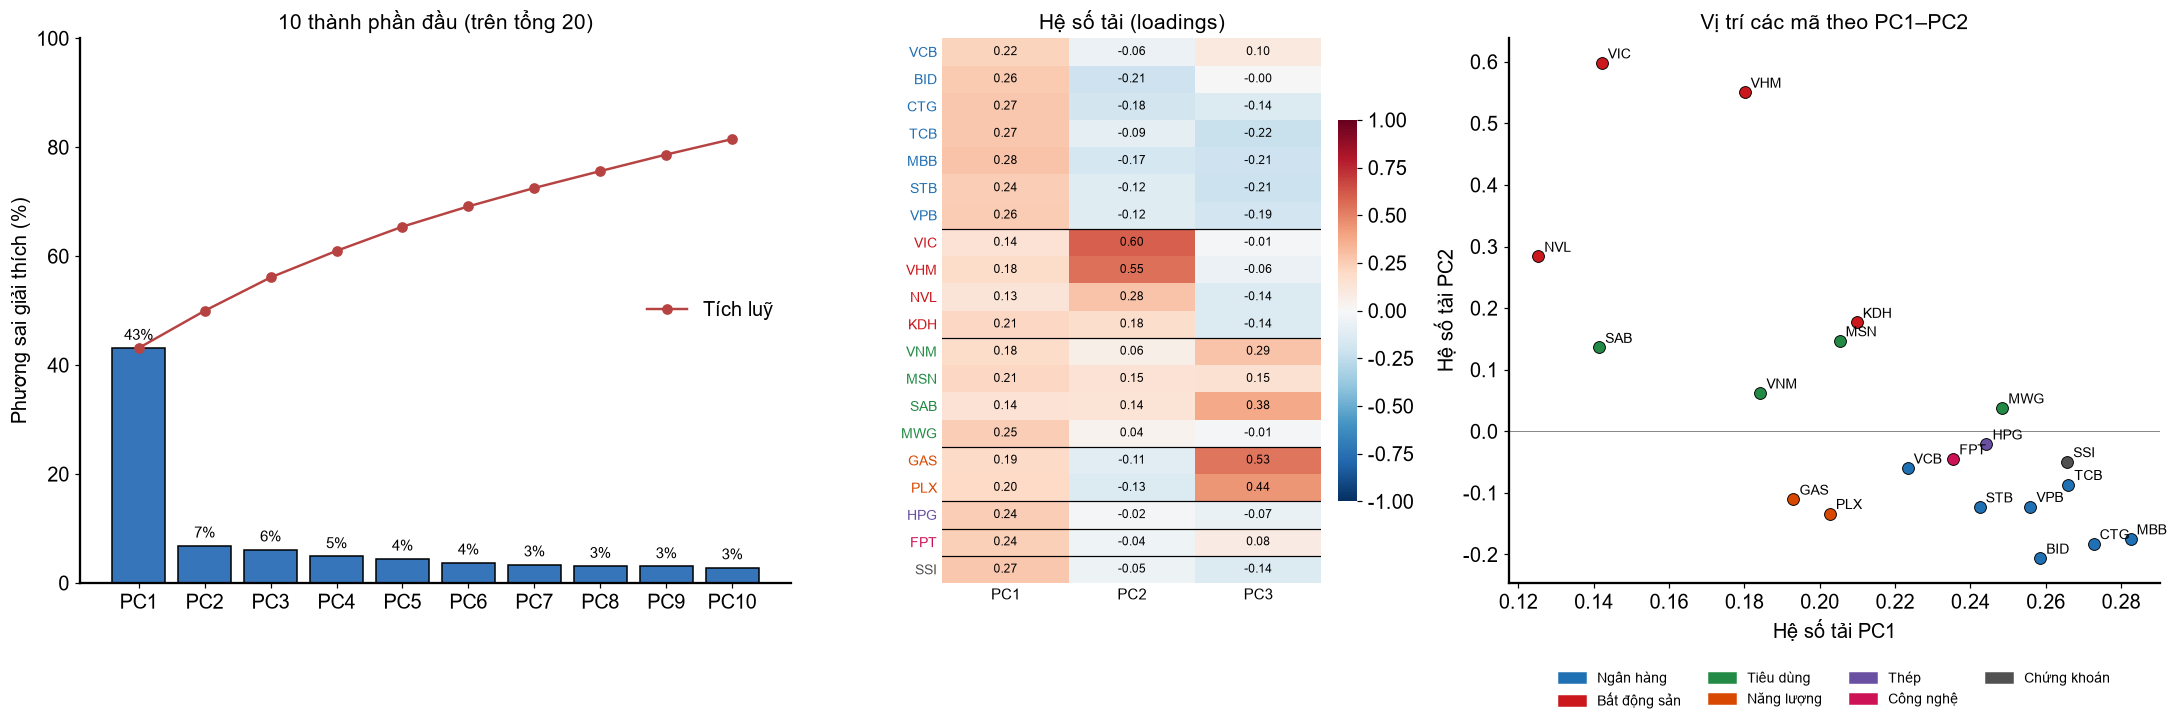

Phương sai giải thích PC1–PC6 (%): [43.1, 6.8, 6.1, 4.9, 4.4, 3.7]
Số PC để đạt 50% / 70% / 80%: 3 / 7 / 10
Ngưỡng Marchenko–Pastur λ_max = 1.20; số trị riêng vượt ngưỡng: 3; λ1 = 8.63
PC1: tải nhỏ nhất / lớn nhất: NVL 0.13 / MBB 0.28
PC1 trung bình theo ngành: {'Ngân hàng': 0.26, 'Bất động sản': 0.16, 'Tiêu dùng': 0.19, 'Năng lượng': 0.2, 'Thép': 0.24, 'Công nghệ': 0.24, 'Chứng khoán': 0.27}
PC2 tải lớn nhất: {'VIC': 0.6, 'VHM': 0.55, 'NVL': 0.28, 'BID': -0.21}
PC3 tải lớn nhất: {'GAS': 0.53, 'PLX': 0.44, 'SAB': 0.38, 'VNM': 0.29}
PC4 tải lớn nhất: {'NVL': 0.62, 'VIC': -0.4, 'KDH': 0.34, 'VHM': -0.3}


,PC1,PC2,PC3,PC4,PC5,PC6
tỷ lệ giải thích,0.4313,0.0683,0.0612,0.0488,0.0444,0.0372


In [11]:
Z = (r - r.mean()) / r.std()
eigval, eigvec = np.linalg.eigh(Z.cov().values)
order = eigval.argsort()[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
eigvec = eigvec * np.sign(eigvec.sum(axis=0))            # cố định dấu cho dễ đọc
explained = eigval / eigval.sum()
loadings = pd.DataFrame(eigvec, index=SYMBOLS, columns=[f"PC{i+1}" for i in range(len(SYMBOLS))])
mp_max = (1 + np.sqrt(len(SYMBOLS) / len(r))) ** 2       # ngưỡng Marchenko–Pastur: trị riêng của nhiễu thuần tuý

fig, axes = plt.subplots(1, 3, figsize=(20, 6.8), gridspec_kw={"width_ratios": [1.2, 0.7, 1.1]})
K = 10
pcs = loadings.columns[:K]
axes[0].bar(pcs, 100 * explained[:K], color=U.PALETTE["blue_secondary"], edgecolor="black", lw=1)
axes[0].plot(pcs, 100 * explained.cumsum()[:K], color=U.PALETTE["red_strong"], marker="o", lw=1.6, label="Tích luỹ")
for i, v in enumerate(explained[:K]):
    axes[0].text(i, 100 * v + 1.5, f"{100*v:.0f}%", ha="center", fontsize=10)
axes[0].set_ylabel("Phương sai giải thích (%)"); axes[0].set_ylim(0, 100)
axes[0].set_title(f"{K} thành phần đầu (trên tổng {len(SYMBOLS)})")
axes[0].legend(loc="center right")
U.make_heatmap(axes[1], loadings[["PC1", "PC2", "PC3"]], vmin=-1, vmax=1, title="Hệ số tải (loadings)")
for t in axes[1].texts: t.set_fontsize(8)
sector_style(axes[1], SYMBOLS, axis="y", sep=False, fs=9)
axes[1].set_xticks(range(3), ["PC1", "PC2", "PC3"], rotation=0, fontsize=10)
for i in range(1, len(SYMBOLS)):
    if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]: axes[1].axhline(i - 0.5, color="black", lw=0.8)
for s in SYMBOLS:
    axes[2].scatter(loadings.loc[s, "PC1"], loadings.loc[s, "PC2"], s=60, color=SC[SECTOR[s]], edgecolor="black", lw=0.6)
    axes[2].annotate(s, (loadings.loc[s, "PC1"], loadings.loc[s, "PC2"]), xytext=(4, 3), textcoords="offset points", fontsize=9)
axes[2].axhline(0, color="gray", lw=0.6); axes[2].set_xlabel("Hệ số tải PC1"); axes[2].set_ylabel("Hệ số tải PC2")
axes[2].set_title("Vị trí các mã theo PC1–PC2")
sector_legend(axes[2], loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, fontsize=9)
U.finalize_figure(fig, "04_pca")
plt.show()
U.save_table(pd.concat([loadings, pd.DataFrame([explained], index=["explained"], columns=loadings.columns)]),
             "04_pca_loadings")
print("Phương sai giải thích PC1–PC6 (%):", (100 * explained[:6]).round(1).tolist())
print(f"Số PC để đạt 50% / 70% / 80%: {int(np.argmax(explained.cumsum() >= .5)) + 1} / {int(np.argmax(explained.cumsum() >= .7)) + 1} / {int(np.argmax(explained.cumsum() >= .8)) + 1}")
print(f"Ngưỡng Marchenko–Pastur λ_max = {mp_max:.2f}; số trị riêng vượt ngưỡng: {(eigval > mp_max).sum()}; λ1 = {eigval[0]:.2f}")
print("PC1: tải nhỏ nhất / lớn nhất:", loadings["PC1"].idxmin(), round(loadings["PC1"].min(), 2), "/", loadings["PC1"].idxmax(), round(loadings["PC1"].max(), 2))
print("PC1 trung bình theo ngành:", loadings["PC1"].groupby(lambda s: SECTOR[s], sort=False).mean().round(2).to_dict())
for pc in ("PC2", "PC3", "PC4"):
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, "tải lớn nhất:", {s: round(float(loadings.loc[s, pc]), 2) for s in top})
pd.Series(explained, index=loadings.columns, name="tỷ lệ giải thích").head(6).to_frame().T

## 7. Quan hệ dẫn–trễ: kiểm định nhân quả Granger (sai số chuẩn HAC)

Với mỗi cặp có hướng $a \to b$, ước lượng một hồi quy với **số lag cố định chọn trước** $p = 5$ (một tuần giao dịch):
$b_t = c + \sum_{i=1}^{p}\beta_i b_{t-i} + \sum_{i=1}^{p}\gamma_i a_{t-i} + \varepsilon_t$, rồi kiểm định Wald
$H_0: \gamma_1 = \dots = \gamma_p = 0$. Dùng sai số chuẩn **HAC (Newey–West)** vì notebook 03 cho thấy có ARCH,
nên F-test thông thường (giả định phương sai đồng nhất) không hợp lệ. Mỗi cặp đúng **một** kiểm định → 20 × 19 = **380 kiểm định**:
ngưỡng Bonferroni $0{,}05/380 \approx 1{,}3\times10^{-4}$; đồng thời báo cáo hiệu chỉnh **Holm** (bớt bảo thủ hơn Bonferroni, vẫn kiểm soát FWER).
Với 380 kiểm định, nếu mọi $H_0$ đúng thì kỳ vọng khoảng $380 \times 0{,}05 = 19$ cặp có $p < 0{,}05$ chỉ do ngẫu nhiên.

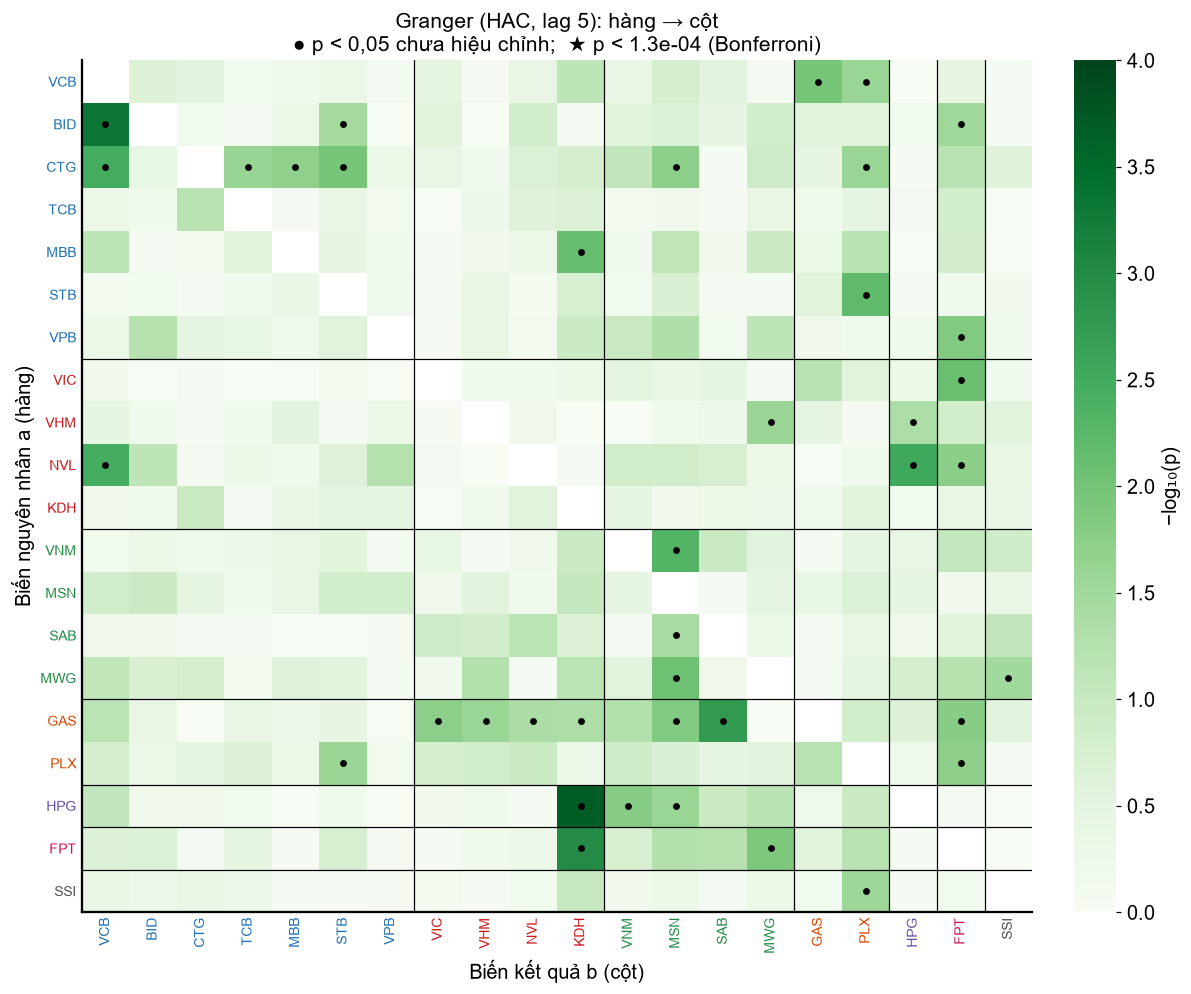

380 kiểm định | p < 0,05: 39 (kỳ vọng ngẫu nhiên ≈ 19) | Bonferroni (p < 1.32e-04): 0 | Holm: 0
Theo nguyên nhân (số p < 0,05): {'GAS': 7, 'CTG': 6, 'BID': 3, 'NVL': 3, 'HPG': 3}
Theo kết quả (số p < 0,05): {'FPT': 6, 'MSN': 6, 'PLX': 4, 'KDH': 4, 'VCB': 3}
Tỷ lệ p < 0,05: cùng ngành 0.132 | khác ngành 0.096
Tương quan trễ 1 phiên |ρ| lớn nhất: 0.109


,nguyên nhân,kết quả,Wald χ²,p (HAC),"corr(a_{t-1}, b_t)",p Holm,có ý nghĩa (Bonferroni),có ý nghĩa (Holm),cùng ngành
333,HPG,KDH,24.1051,0.0002,0.1086,0.0788,False,False,False
19,BID,VCB,22.2086,0.0005,0.0635,0.1811,False,False,True
352,FPT,KDH,20.4564,0.0010,0.0935,0.3877,False,False,False
298,GAS,SAB,19.2520,0.0017,0.0657,0.6504,False,False,False
187,NVL,HPG,17.9001,0.0031,-0.0110,1.0000,False,False,False
171,NVL,VCB,17.6774,0.0034,-0.0004,1.0000,False,False,False
38,CTG,VCB,17.5860,0.0035,0.0538,1.0000,False,False,True
220,VNM,MSN,16.7313,0.0050,0.0576,1.0000,False,False,True


In [12]:
LAG = 5
lagged = {s: pd.concat({f"{s}_l{i}": r[s].shift(i) for i in range(1, LAG + 1)}, axis=1) for s in SYMBOLS}
rows = []
for a in SYMBOLS:
    for b in SYMBOLS:
        if a == b: continue
        X = sm.add_constant(pd.concat([lagged[b], lagged[a]], axis=1)).dropna()
        y = r[b].loc[X.index]
        fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        wald = fit.wald_test(" = 0, ".join(lagged[a].columns) + " = 0", scalar=True)
        rows.append({"nguyên nhân": a, "kết quả": b, "Wald χ²": wald.statistic, "p (HAC)": wald.pvalue,
                     "corr(a_{t-1}, b_t)": r[a].shift(1).corr(r[b])})
granger = pd.DataFrame(rows)
BONF = 0.05 / len(granger)
granger["p Holm"] = multipletests(granger["p (HAC)"], method="holm")[1]
granger["có ý nghĩa (Bonferroni)"] = granger["p (HAC)"] < BONF
granger["có ý nghĩa (Holm)"] = granger["p Holm"] < 0.05
granger["cùng ngành"] = [SECTOR[a] == SECTOR[b] for a, b in zip(granger["nguyên nhân"], granger["kết quả"])]
U.save_table(granger.set_index(["nguyên nhân", "kết quả"]), "04_granger")
pmat = granger.pivot(index="nguyên nhân", columns="kết quả", values="p (HAC)").loc[SYMBOLS, SYMBOLS]
nlp = -np.log10(pmat)

fig, ax = plt.subplots(figsize=(11, 9.2))
im = ax.imshow(nlp.values, cmap="Greens", vmin=0, vmax=4, aspect="auto")
for i in range(len(SYMBOLS)):
    for j in range(len(SYMBOLS)):
        p = pmat.values[i, j]
        if np.isnan(p): continue
        if p < BONF: ax.plot(j, i, marker="*", ms=11, color=U.PALETTE["red_strong"], mec="black", mew=0.4)
        elif p < 0.05: ax.plot(j, i, marker="o", ms=3.5, color="black")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("−log₁₀(p)"); cb.outline.set_visible(False)
ax.tick_params(length=0)
sector_style(ax, SYMBOLS)
ax.set_xlabel("Biến kết quả b (cột)"); ax.set_ylabel("Biến nguyên nhân a (hàng)")
ax.set_title(f"Granger (HAC, lag {LAG}): hàng → cột\n● p < 0,05 chưa hiệu chỉnh;  ★ p < {BONF:.1e} (Bonferroni)")
U.finalize_figure(fig, "04_granger_pvalues")
plt.show()
nsig = int((granger["p (HAC)"] < 0.05).sum())
print(f"{len(granger)} kiểm định | p < 0,05: {nsig} (kỳ vọng ngẫu nhiên ≈ {0.05 * len(granger):.0f}) | Bonferroni (p < {BONF:.2e}): {int(granger['có ý nghĩa (Bonferroni)'].sum())} | Holm: {int(granger['có ý nghĩa (Holm)'].sum())}")
print("Theo nguyên nhân (số p < 0,05):", granger[granger["p (HAC)"] < .05]["nguyên nhân"].value_counts().head(5).to_dict())
print("Theo kết quả (số p < 0,05):", granger[granger["p (HAC)"] < .05]["kết quả"].value_counts().head(5).to_dict())
print("Tỷ lệ p < 0,05: cùng ngành %.3f | khác ngành %.3f" % tuple(granger.groupby("cùng ngành")["p (HAC)"].apply(lambda p: (p < .05).mean()).reindex([True, False])))
print("Tương quan trễ 1 phiên |ρ| lớn nhất: %.3f" % granger["corr(a_{t-1}, b_t)"].abs().max())
granger.sort_values("p (HAC)").head(8)

Lưu ý: Granger chỉ là **dự báo được** theo nghĩa tuyến tính, không phải nhân quả cấu trúc; nhân tố
thị trường chung (PC1) và biến động cụm vẫn có thể tạo quan hệ giả.

## 8. Quan hệ khối lượng – biến động

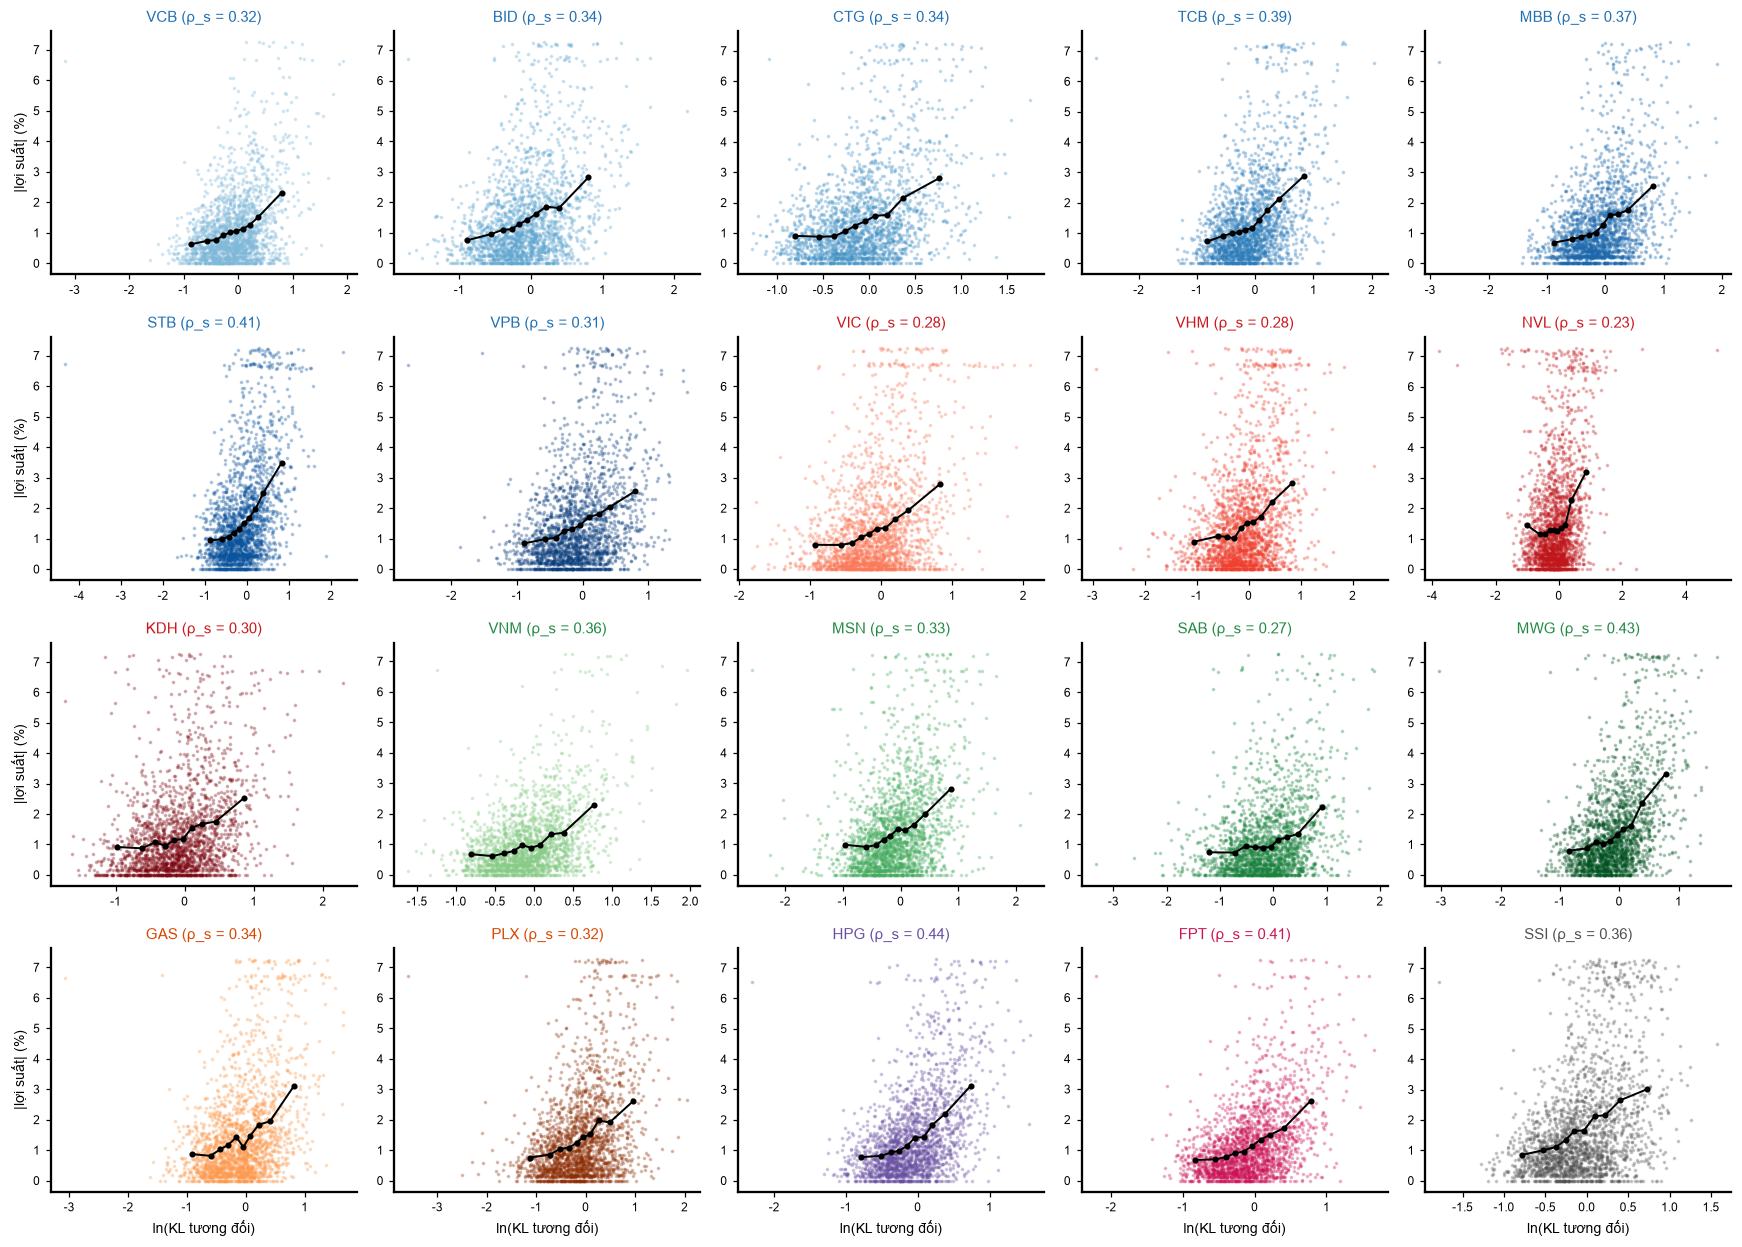

Spearman ρ: min 0.23 (NVL) | max 0.44 (HPG) | trung bình 0.34; số mã p < 0,001: 20/20
Trung bình theo ngành: {'Ngân hàng': 0.35, 'Bất động sản': 0.27, 'Tiêu dùng': 0.35, 'Năng lượng': 0.33, 'Thép': 0.44, 'Công nghệ': 0.41, 'Chứng khoán': 0.36}


,ngành,Spearman ρ,p,|r| decile 1 (%),|r| decile 10 (%),tỷ số D10/D1
symbol,,,,,,
VCB,Ngân hàng,0.3157,0.0000,0.6247,2.3111,3.6996
BID,Ngân hàng,0.3429,0.0000,0.7585,2.8172,3.7144
CTG,Ngân hàng,0.3431,0.0000,0.9036,2.8061,3.1056
TCB,Ngân hàng,0.3878,0.0000,0.7192,2.8890,4.0172
MBB,Ngân hàng,0.3681,0.0000,0.6791,2.5585,3.7677
STB,Ngân hàng,0.4068,0.0000,0.9367,3.4798,3.7148
VPB,Ngân hàng,0.3111,0.0000,0.8462,2.5613,3.0267
VIC,Bất động sản,0.2828,0.0000,0.7966,2.7929,3.5063
VHM,Bất động sản,0.2828,0.0000,0.8999,2.8216,3.1354


In [13]:
vv = con.execute("""
    SELECT symbol, ABS(log_ret) AS abs_ret, LN(rel_volume) AS log_rel_vol
    FROM v_analysis WHERE rel_volume > 0""").df()
fig, axes = plt.subplots(4, 5, figsize=(16, 11.5))
rows = []
for ax, s in zip(axes.ravel(), SYMBOLS):
    d = vv[vv.symbol == s]
    ax.scatter(d.log_rel_vol, 100 * d.abs_ret, s=2, alpha=0.25, color=COL[s])
    bins = pd.qcut(d.log_rel_vol, 10)
    m = d.groupby(bins, observed=True).agg(x=("log_rel_vol", "mean"), y=("abs_ret", "mean"))
    ax.plot(m.x, 100 * m.y, color="black", marker="o", ms=3, lw=1.3)
    rho = stats.spearmanr(d.log_rel_vol, d.abs_ret)
    rows.append({"symbol": s, "ngành": SECTOR[s], "Spearman ρ": rho.statistic, "p": rho.pvalue,
                 "|r| decile 1 (%)": 100 * m.y.iloc[0], "|r| decile 10 (%)": 100 * m.y.iloc[-1],
                 "tỷ số D10/D1": m.y.iloc[-1] / m.y.iloc[0]})
    ax.set_title(f"{s} (ρ_s = {rho.statistic:.2f})", fontsize=10, color=SC[SECTOR[s]])
    ax.tick_params(labelsize=8)
for ax in axes[-1]: ax.set_xlabel("ln(KL tương đối)", fontsize=9)
for ax in axes[:, 0]: ax.set_ylabel("|lợi suất| (%)", fontsize=9)
U.finalize_figure(fig, "04_volume_volatility")
plt.show()
vvt = pd.DataFrame(rows).set_index("symbol")
U.save_table(vvt, "04_volume_volatility")
print("Spearman ρ: min %.2f (%s) | max %.2f (%s) | trung bình %.2f; số mã p < 0,001: %d/20" % (
    vvt["Spearman ρ"].min(), vvt["Spearman ρ"].idxmin(), vvt["Spearman ρ"].max(), vvt["Spearman ρ"].idxmax(),
    vvt["Spearman ρ"].mean(), (vvt.p < 1e-3).sum()))
print("Trung bình theo ngành:", vvt.groupby("ngành", sort=False)["Spearman ρ"].mean().round(2).to_dict())
vvt

## 9. Nhận xét

(20 mã, 2.118 phiên chung, 190 cặp không có hướng: 34 cùng ngành, 156 khác ngành.)

- **Cấu trúc tương quan theo ngành:** Pearson giữa các cặp nằm trong 0,13–0,74 (trung vị 0,37, trung bình 0,385; Spearman TB 0,337, Kendall TB 0,237), **toàn bộ dương**.
  Trung bình cặp cùng ngành là 0,50 so với 0,36 ở cặp khác ngành. Cao nhất là nhóm ngân hàng: CTG–MBB 0,74, TCB–MBB 0,73, BID–CTG 0,71, MBB–VPB 0,67 (trung bình trong ngành ngân hàng 0,59);
  GAS–PLX 0,64 (năng lượng) và VIC–VHM 0,62 (cùng hệ Vingroup). Ngân hàng cũng tương quan cao với SSI (0,57 trung bình, MBB–SSI 0,65) và HPG–SSI 0,61, tức là các cổ phiếu "beta cao" của chu kỳ tín dụng/thị trường đi cùng nhau.
  Thấp nhất luôn có NVL: NVL–GAS 0,13, NVL–SAB 0,16, NVL–PLX 0,17, NVL–VNM 0,17; cùng với VIC–GAS 0,19, VIC–SAB 0,19. Nhóm bất động sản là ngành **kém gắn kết nhất** (tương quan trong ngành chỉ 0,33, thấp hơn cả tiêu dùng 0,34) và có tương quan thấp nhất với mọi ngành khác (0,21–0,35).
- **Tương quan động (cửa sổ 120 phiên):** tương quan trung bình của 190 cặp thay đổi theo thời gian từ 0,21 (19/11/2019) đến 0,61 (11/04/2025), trung bình cả kỳ 0,38; theo năm: 0,30 (2019), 0,45 (2020, COVID), 0,42 (2025), 0,32 (2026).
  Tương quan cùng ngành luôn cao hơn khác ngành, chênh lệch trung bình 0,12 (0,48 so với 0,36) → các mã đi cùng nhau mạnh hơn trong những giai đoạn khủng hoảng thị trường.
- **PCA:** PC1 giải thích **43,1%** phương sai (λ₁ = 8,63, ngưỡng nhiễu Marchenko–Pastur chỉ 1,20), hệ số tải cùng dấu dương ở cả 20 mã (0,13–0,28): đây là **nhân tố thị trường**. Tải lớn nhất ở MBB (0,28), SSI (0,27), CTG/TCB (0,27), nhỏ nhất ở NVL (0,13); trung bình theo ngành: chứng khoán 0,27, ngân hàng 0,26, thép 0,24, công nghệ 0,24, năng lượng 0,20, tiêu dùng 0,19, bất động sản 0,16.
  Chỉ 3 trị riêng vượt ngưỡng nhiễu: PC2 (6,8%) là nhân tố **Vingroup/bất động sản** (VIC 0,60, VHM 0,55, NVL 0,28), PC3 (6,1%) là nhân tố **năng lượng–tiêu dùng phòng thủ** (GAS 0,53, PLX 0,44, SAB 0,38, VNM 0,29); NVL tách riêng ở PC4 (0,62, 4,9%).
  Cần 3 / 7 / 10 thành phần để đạt 50% / 70% / 80% phương sai. So với mẫu 5 mã (PC1 ~49%, PC2 ≈ NVL, PC3 ≈ VHM), mở rộng lên 20 mã cho thấy nhân tố chung loãng đi và cấu trúc ngành rõ hơn.
- **Phụ thuộc đuôi:** λ̂_L ở q = 5% trung bình **0,37** (độc lập sẽ là 0,05), cao hơn mức Gaussian copula (trung bình 0,17) ở **cả 190/190 cặp** (chênh lệch +0,01 đến +0,35, trung bình +0,20; tỷ số 1,1–3,2 lần). CI 95% bootstrap khối (B = 1.000, khối 20 phiên) loại trừ 0 ở 184/190 cặp
  (từng cặp riêng lẻ, chưa hiệu chỉnh đa kiểm định). Cặp cùng ngành: λ̂_L = 0,47 so với Gauss 0,23 (CI > 0 ở 33/34); khác ngành: 0,35 so với 0,16 (151/156). Mạnh nhất: TCB–MBB 0,68, BID–CTG 0,66, CTG–MBB 0,65, MBB–STB 0,65, MBB–SSI 0,64 — khi một trong hai mã rơi vào 5% phiên tệ nhất, hai phần ba số lần mã kia cũng vậy.
  **Sáu cặp không có bằng chứng** vượt Gaussian đều chứa NVL (với VCB, BID, CTG, VIC, GAS, FPT; ví dụ NVL–GAS λ̂_L = 0,10 so với 0,09) → NVL gần như chỉ phụ thuộc đuôi ở mức Gaussian vào phần còn lại của thị trường, phù hợp với việc NVL mang rủi ro riêng (khủng hoảng 2022).
- **Tương quan có điều kiện:** trong 212 phiên thị trường xấu nhất (10%), tương quan trung bình các cặp là 0,31, cao hơn 0,24 của các phiên còn lại (lưu ý cả hai đều thấp hơn 0,385 toàn mẫu vì cắt theo biến thị trường làm lệch chọn mẫu); tương quan tăng ở 157/190 cặp (+0,08 cùng ngành, +0,07 khác ngành),
  tăng mạnh nhất ở SAB–FPT (+0,32), STB–PLX (+0,26), VNM–FPT (+0,25), STB–KDH (+0,24), giảm ở 33 cặp, trong đó 15 cặp có NVL hoặc VCB (NVL–GAS −0,18, VCB–NVL −0,16, VCB–SSI −0,16, BID–NVL −0,15). Do sai lệch chọn mẫu, nên đánh giá lây lan khi căng thẳng bằng λ̂_L hoặc copula thay vì so trực tiếp.
- **Dẫn–trễ (380 cặp có hướng):** 39 cặp có p < 0,05 (10,3%, so với 5% ≈ 19 cặp kỳ vọng ngẫu nhiên), nhưng **không cặp nào** đạt ngưỡng Bonferroni (p < 1,3·10⁻⁴) hay Holm. Nhỏ nhất: HPG→KDH (p ≈ 2·10⁻⁴, Holm 0,08), BID→VCB (5·10⁻⁴, Holm 0,18), FPT→KDH (0,001), GAS→SAB (0,002).
  Dấu hiệu tập trung: GAS là "nguyên nhân" của 7 cặp có p < 0,05, CTG của 6; FPT và MSN là biến kết quả của 6 cặp mỗi mã. Tỷ lệ p < 0,05 ở cặp cùng ngành 13,2%, khác ngành 9,6%. Tương quan trễ một phiên rất nhỏ (|ρ| ≤ 0,11) → không có bằng chứng đủ mạnh về dự báo tuyến tính giữa các mã ở tần suất ngày;
  số lượng p < 0,05 vượt kỳ vọng cho thấy có thể có quan hệ yếu rải rác, cần kiểm tra thêm (ví dụ sau khi lọc GARCH và kiểm soát nhân tố thị trường) trước khi diễn giải.
- **Khối lượng – biến động:** |lợi suất| tăng theo khối lượng tương đối ở cả 20 mã (Spearman ρ = 0,23–0,44, trung bình 0,34, p < 0,001 ở 20/20), mạnh nhất HPG (0,44), MWG (0,43), FPT (0,41), STB (0,41), yếu nhất NVL (0,23), VIC/VHM (0,28), SAB (0,27). Theo ngành: thép 0,44, công nghệ 0,41, chứng khoán 0,36, ngân hàng 0,35, tiêu dùng 0,35, năng lượng 0,33, bất động sản 0,27.
  |r| ở decile khối lượng cao nhất gấp 2,2 lần (NVL) đến 4,2 lần (MWG) decile thấp nhất. Quan hệ không đơn điệu ở đầu thấp của NVL (decile 1 có |r| = 1,45%, cao nhất trong 20 mã). Phù hợp giả thuyết phân phối hỗn hợp (mixture of distributions hypothesis).
- **Gợi ý cho bước sau:** phân tích phụ thuộc/nhân quả nên xử lý (i) đuôi bị chặn ±7%, (ii) biến động cụm (lọc GARCH trước), (iii) nhân tố thị trường chung (PC1, 43% phương sai) và nhân tố ngành (PC2–PC3) để tránh tương quan giả; NVL nên được xem như trường hợp đặc biệt.